# 🏆 06 — Model Comparison (3 Models) + Final Retrain on All Data

> **Mục tiêu:**
> 1. Load `best_model.h5` của **3 model**: Vanilla LSTM, BiLSTM, Transformer
> 2. Đánh giá cả 3 trên **test set** (accuracy, F1, confusion matrix)
> 3. Chọn winner (theo F1 Macro)
> 4. **Retrain winner trên toàn bộ data** (train+val+test) → `final_model.h5`
>
> **Input:** `data/processed/X_*.npy`, `models/lstm_vanilla/`, `models/lstm/`, `models/transformer/`
> **Output:** `models/{winner}/final_model.h5`, `reports/comparison_report.json`

In [1]:
# ==== CELL 1: Cài thư viện ====
import subprocess, sys
pkgs = ['tensorflow', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn']
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet'] + pkgs, check=True)
print('Packages OK')

Packages OK


In [2]:
# ==== CELL 2: Import ====
import os, json, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None (CPU mode)')

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow: 2.21.0
GPU: None (CPU mode)


In [3]:
# ==== CELL 3: Custom layers/classes (copy từ notebook 04) ====
# Cần define lại để load_model biết cách reconstruct Transformer

class PositionalEncoding(layers.Layer):
    """Learnable positional encoding."""
    def __init__(self, max_len, embed_dim, **kw):
        super().__init__(**kw)
        self.max_len   = max_len
        self.embed_dim = embed_dim

    def build(self, input_shape):
        self.pos_emb = self.add_weight(
            shape=(1, self.max_len, self.embed_dim),
            initializer='uniform', trainable=True, name='pos_emb'
        )

    def call(self, x):
        return x + self.pos_emb[:, :tf.shape(x)[1], :]

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'max_len': self.max_len, 'embed_dim': self.embed_dim})
        return cfg


class TransformerEncoderBlock(layers.Layer):
    """1 Transformer Encoder block: MHA + FFN + LayerNorm."""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1, **kw):
        super().__init__(**kw)
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim    = ff_dim
        self.dropout   = dropout
        self.att   = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.ffn   = keras.Sequential([
            layers.Dense(ff_dim, activation='gelu'),
            layers.Dropout(dropout),
            layers.Dense(embed_dim),
        ])
        self.ln1   = layers.LayerNormalization(epsilon=1e-6)
        self.ln2   = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, training=False):
        attn_out = self.att(x, x, training=training)
        x = self.ln1(x + self.drop1(attn_out, training=training))
        ffn_out = self.ffn(x, training=training)
        return self.ln2(x + self.drop2(ffn_out, training=training))

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'embed_dim': self.embed_dim, 'num_heads': self.num_heads,
                    'ff_dim': self.ff_dim, 'dropout': self.dropout})
        return cfg


class WarmupCosineDecay(keras.optimizers.schedules.LearningRateSchedule):
    """Warmup + Cosine Decay LR schedule."""
    def __init__(self, lr_max, warmup_steps, total_steps):
        super().__init__()
        self.lr_max       = float(lr_max)
        self.warmup_steps = float(warmup_steps)
        self.total_steps  = float(total_steps)

    def __call__(self, step):
        step      = tf.cast(step, tf.float32)
        warmup_lr = self.lr_max * step / self.warmup_steps
        progress  = (step - self.warmup_steps) / (self.total_steps - self.warmup_steps)
        cosine_lr = self.lr_max * 0.5 * (1.0 + tf.cos(np.pi * progress))
        return tf.where(step < self.warmup_steps, warmup_lr, cosine_lr)

    def get_config(self):
        return {'lr_max': self.lr_max, 'warmup_steps': self.warmup_steps,
                'total_steps': self.total_steps}


CUSTOM_OBJECTS = {
    'PositionalEncoding': PositionalEncoding,
    'TransformerEncoderBlock': TransformerEncoderBlock,
    'WarmupCosineDecay': WarmupCosineDecay,
}
print('Custom layers defined OK')

Custom layers defined OK


In [4]:
# ==== CELL 4: Config ====
BASE       = r'd:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment'
DATA_DIR   = os.path.join(BASE, 'data', 'processed')
MODEL_DIR  = os.path.join(BASE, 'models')
REPORT_DIR = os.path.join(BASE, 'reports')
os.makedirs(REPORT_DIR, exist_ok=True)

LABEL_MAP   = {0: 'push-up', 1: 'lateral raise', 2: 'squat', 3: 'pull Up', 4: 'leg raises'}
N_CLASSES   = 5
INPUT_SHAPE = (30, 99)

print('Base dir  :', BASE)
print('Data dir  :', DATA_DIR)
print('Report dir:', REPORT_DIR)

Base dir  : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment
Data dir  : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\data\processed
Report dir: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\reports


In [5]:
# ==== CELL 5: Load Data ====
X_train = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
X_val   = np.load(os.path.join(DATA_DIR, 'X_val.npy'))
X_test  = np.load(os.path.join(DATA_DIR, 'X_test.npy'))
y_train = np.load(os.path.join(DATA_DIR, 'y_train.npy'))
y_val   = np.load(os.path.join(DATA_DIR, 'y_val.npy'))
y_test  = np.load(os.path.join(DATA_DIR, 'y_test.npy'))

print('=== DATA LOADED ===')
print(f'X_train : {X_train.shape}  |  X_val : {X_val.shape}  |  X_test : {X_test.shape}')

# Ghep ALL data de retrain sau
X_all = np.concatenate([X_train, X_val, X_test], axis=0)
y_all = np.concatenate([y_train, y_val, y_test], axis=0)
print(f'X_all   : {X_all.shape}  (train+val+test combined)')

=== DATA LOADED ===
X_train : (19224, 30, 99)  |  X_val : (1247, 30, 99)  |  X_test : (1061, 30, 99)
X_all   : (21532, 30, 99)  (train+val+test combined)


In [6]:
# ==== CELL 6: Evaluate helper ====
def evaluate_model(model, X_t, y_t, model_name):
    sep = '=' * 55
    print(f'\n{sep}')
    print(f'  Evaluating: {model_name}')
    print(sep)

    y_prob = model.predict(X_t, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    acc    = accuracy_score(y_t, y_pred)
    f1_mac = f1_score(y_t, y_pred, average='macro')
    f1_wt  = f1_score(y_t, y_pred, average='weighted')

    print(f'  Accuracy        : {acc:.4f}  ({acc*100:.2f}%)')
    print(f'  F1 Macro        : {f1_mac:.4f}')
    print(f'  F1 Weighted     : {f1_wt:.4f}')
    print()
    print(classification_report(
        y_t, y_pred,
        target_names=[LABEL_MAP[i] for i in range(N_CLASSES)]
    ))
    return {
        'model': model_name,
        'accuracy': float(acc),
        'f1_macro': float(f1_mac),
        'f1_weighted': float(f1_wt),
        'y_pred': y_pred.tolist(),
        'confusion_matrix': confusion_matrix(y_t, y_pred).tolist()
    }

print('evaluate_model() ready')

evaluate_model() ready


In [7]:
# ==== CELL 7: Load & Evaluate LSTM ====
lstm_path = os.path.join(MODEL_DIR, 'lstm', 'best_model.h5')

if not os.path.exists(lstm_path):
    print(f'SKIP: {lstm_path} not found — chay notebook 03 truoc!')
    lstm_results = None
else:
    print(f'Loading LSTM: {lstm_path}')
    # LSTM khong dung custom layer nen load binh thuong
    lstm_model   = keras.models.load_model(lstm_path)
    lstm_results = evaluate_model(lstm_model, X_test, y_test, 'BiLSTM')

Loading LSTM: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm\best_model.h5



  Evaluating: BiLSTM
  Accuracy        : 0.7936  (79.36%)
  F1 Macro        : 0.7920
  F1 Weighted     : 0.7901

               precision    recall  f1-score   support

      push-up       0.96      0.91      0.93       289
lateral raise       1.00      0.77      0.87       171
        squat       0.60      0.87      0.71       238
      pull Up       0.84      0.98      0.90       149
   leg raises       0.70      0.45      0.55       214

     accuracy                           0.79      1061
    macro avg       0.82      0.79      0.79      1061
 weighted avg       0.82      0.79      0.79      1061



In [8]:
# ==== CELL 8: Load & Evaluate Transformer ====
transformer_path = os.path.join(MODEL_DIR, 'transformer', 'best_model.h5')

if not os.path.exists(transformer_path):
    print(f'SKIP: {transformer_path} not found — chay notebook 04 truoc!')
    transformer_results = None
else:
    print(f'Loading Transformer: {transformer_path}')
    # Truyen custom_objects de Keras biet cach reconstruct
    transformer_model   = keras.models.load_model(
        transformer_path,
        custom_objects=CUSTOM_OBJECTS
    )
    transformer_results = evaluate_model(transformer_model, X_test, y_test, 'Transformer')

Loading Transformer: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\best_model.h5




  Evaluating: Transformer
  Accuracy        : 0.9434  (94.34%)
  F1 Macro        : 0.9400
  F1 Weighted     : 0.9435

               precision    recall  f1-score   support

      push-up       0.99      0.99      0.99       289
lateral raise       0.95      0.88      0.92       171
        squat       0.88      0.94      0.91       238
      pull Up       0.93      0.97      0.95       149
   leg raises       0.96      0.92      0.94       214

     accuracy                           0.94      1061
    macro avg       0.94      0.94      0.94      1061
 weighted avg       0.94      0.94      0.94      1061



In [9]:
# ==== CELL 8b: Load & Evaluate Vanilla LSTM ====
vanilla_path = os.path.join(MODEL_DIR, 'lstm_vanilla', 'best_model.h5')

if not os.path.exists(vanilla_path):
    print(f'SKIP: {vanilla_path} not found — chay notebook 05 truoc!')
    vanilla_results = None
else:
    print(f'Loading Vanilla LSTM: {vanilla_path}')
    vanilla_model   = keras.models.load_model(vanilla_path)
    vanilla_results = evaluate_model(vanilla_model, X_test, y_test, 'Vanilla LSTM')

Loading Vanilla LSTM: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\best_model.h5

  Evaluating: Vanilla LSTM
  Accuracy        : 0.8435  (84.35%)
  F1 Macro        : 0.8309
  F1 Weighted     : 0.8393

               precision    recall  f1-score   support

      push-up       0.98      0.97      0.97       289
lateral raise       0.78      0.79      0.79       171
        squat       0.77      0.85      0.81       238
      pull Up       0.79      0.99      0.88       149
   leg raises       0.85      0.60      0.71       214

     accuracy                           0.84      1061
    macro avg       0.83      0.84      0.83      1061
 weighted avg       0.85      0.84      0.84      1061



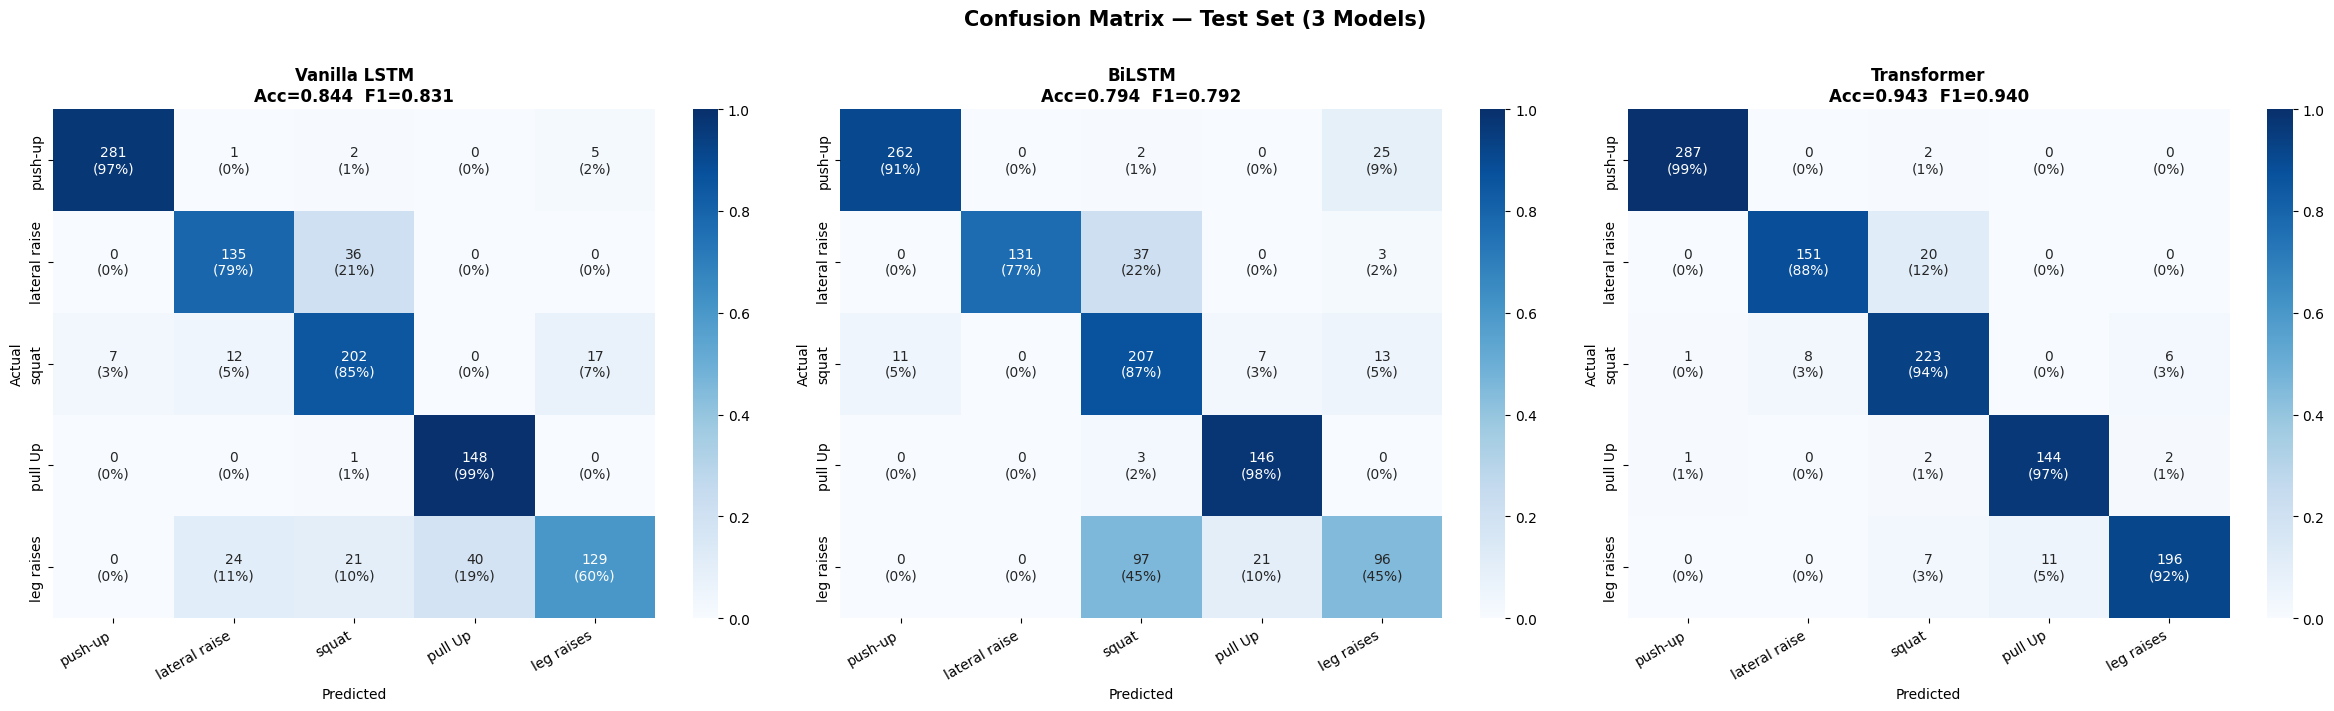

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\reports\comparison_confusion_matrix.png


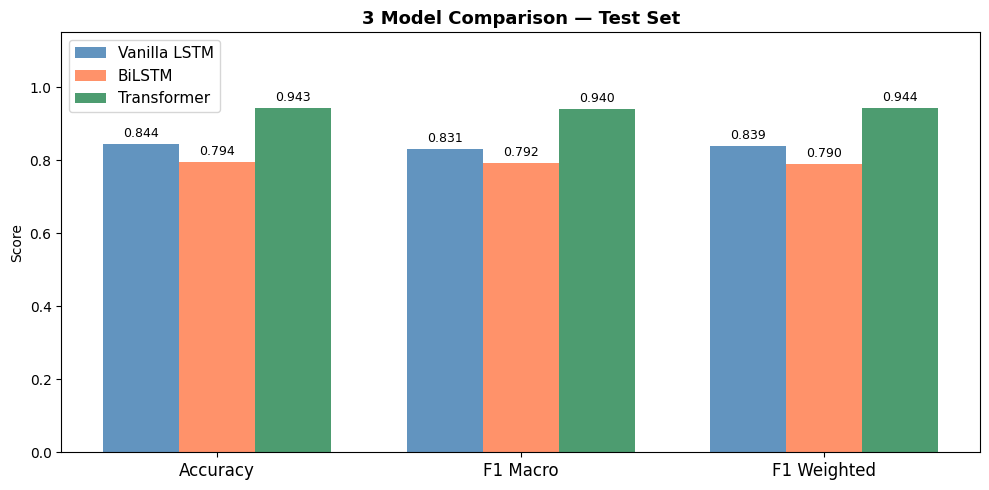

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\reports\comparison_bar.png


In [10]:
# ==== CELL 9: So sanh truc quan (3 model) ====
results_list = [r for r in [vanilla_results, lstm_results, transformer_results] if r is not None]

if not results_list:
    print('Chua co model nao de so sanh!')
else:
    class_names = [LABEL_MAP[i] for i in range(N_CLASSES)]
    fig, axes = plt.subplots(1, len(results_list), figsize=(8 * len(results_list), 7))
    if len(results_list) == 1:
        axes = [axes]

    for ax, res in zip(axes, results_list):
        cm = np.array(res['confusion_matrix'])
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        annot = [[f'{cm[i,j]}\n({cm_norm[i,j]:.0%})' for j in range(N_CLASSES)] for i in range(N_CLASSES)]
        sns.heatmap(
            cm_norm, annot=annot, fmt='', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax,
            vmin=0, vmax=1
        )
        ax.set_title(
            f"{res['model']}\nAcc={res['accuracy']:.3f}  F1={res['f1_macro']:.3f}",
            fontsize=12, fontweight='bold'
        )
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

    plt.suptitle('Confusion Matrix — Test Set (3 Models)', fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()
    report_png = os.path.join(REPORT_DIR, 'comparison_confusion_matrix.png')
    plt.savefig(report_png, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'Saved: {report_png}')

    # Bar chart so sanh 3 model
    if len(results_list) >= 2:
        metrics       = ['accuracy', 'f1_macro', 'f1_weighted']
        metric_labels = ['Accuracy', 'F1 Macro', 'F1 Weighted']
        x     = np.arange(len(metrics))
        width = 0.25
        colors = ['steelblue', 'coral', 'seagreen']
        fig2, ax2 = plt.subplots(figsize=(10, 5))
        for j, (res, color) in enumerate(zip(results_list, colors)):
            offset = (j - len(results_list)/2 + 0.5) * width
            bars = ax2.bar(x + offset, [res[m] for m in metrics],
                           width, label=res['model'], color=color, alpha=0.85)
            ax2.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
        ax2.set_ylim(0, 1.15)
        ax2.set_xticks(x); ax2.set_xticklabels(metric_labels, fontsize=12)
        ax2.set_ylabel('Score'); ax2.legend(fontsize=11)
        ax2.set_title('3 Model Comparison — Test Set', fontsize=13, fontweight='bold')
        plt.tight_layout()
        bar_png = os.path.join(REPORT_DIR, 'comparison_bar.png')
        plt.savefig(bar_png, dpi=120, bbox_inches='tight')
        plt.show()
        print(f'Saved: {bar_png}')

In [11]:
# ==== CELL 10: Chon WINNER ====
if not results_list:
    raise RuntimeError('Khong co model nao — chay 03 va 04 truoc!')

winner_res    = max(results_list, key=lambda r: r['f1_macro'])
WINNER_NAME   = winner_res['model']
WINNER_FOLDER = 'lstm' if 'LSTM' in WINNER_NAME or 'BiLSTM' in WINNER_NAME else 'transformer'
WINNER_MODEL  = lstm_model if WINNER_FOLDER == 'lstm' else transformer_model

print('=' * 55)
print(f'  WINNER: {WINNER_NAME}')
print(f'  Accuracy : {winner_res["accuracy"]:.4f}')
print(f'  F1 Macro : {winner_res["f1_macro"]:.4f}')
print('=' * 55)
print()
print(f'{"Model":<17} {"Accuracy":>10} {"F1 Macro":>10} {"F1 Weighted":>12}')
for r in results_list:
    mark = ' <== WINNER' if r['model'] == WINNER_NAME else ''
    print(f'{r["model"]+mark:<28} {r["accuracy"]:>10.4f} {r["f1_macro"]:>10.4f} {r["f1_weighted"]:>12.4f}')

  WINNER: Transformer
  Accuracy : 0.9434
  F1 Macro : 0.9400

Model               Accuracy   F1 Macro  F1 Weighted
Vanilla LSTM                     0.8435     0.8309       0.8393
BiLSTM                           0.7936     0.7920       0.7901
Transformer <== WINNER           0.9434     0.9400       0.9435


In [12]:
# ==== CELL 11: Luu comparison report (TRUOC khi retrain) ====
# Luu ngay sau khi chon winner, TRUOC retrain
# De sau nay co the xem lai ket qua so sanh bat ky luc nao

comparison_report = {
    'winner': WINNER_NAME,
    'winner_folder': WINNER_FOLDER,
    'test_set_size': int(len(X_test)),
    'models': {
        r['model']: {
            'accuracy': r['accuracy'],
            'f1_macro': r['f1_macro'],
            'f1_weighted': r['f1_weighted'],
            'confusion_matrix': r['confusion_matrix']
        }
        for r in results_list
    }
}

report_path = os.path.join(REPORT_DIR, 'comparison_report.json')
with open(report_path, 'w', encoding='utf-8') as f:
    json.dump(comparison_report, f, indent=2, ensure_ascii=False)

print('Saved comparison_report.json (TRUOC retrain)')
print(f'Path: {report_path}')

Saved comparison_report.json (TRUOC retrain)
Path: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\reports\comparison_report.json


In [13]:
# ==== CELL 12: Doc best epoch cua winner ====
history_path = os.path.join(MODEL_DIR, WINNER_FOLDER, 'training_history.json')
with open(history_path) as f:
    history_data = json.load(f)

val_acc_list = history_data.get('val_accuracy', [])
BEST_EPOCH   = int(max(range(len(val_acc_list)), key=lambda i: val_acc_list[i])) + 1

print(f'Winner: {WINNER_NAME} ({WINNER_FOLDER})')
print(f'Total epochs trained : {len(val_acc_list)}')
print(f'Best epoch           : {BEST_EPOCH}  (peak val_accuracy)')
print(f'Peak val_accuracy    : {max(val_acc_list):.4f}')
print()
print(f'=> Se retrain {BEST_EPOCH} epoch tren {len(X_all):,} samples (100% data)')

Winner: Transformer (transformer)
Total epochs trained : 68
Best epoch           : 48  (peak val_accuracy)
Peak val_accuracy    : 0.9246

=> Se retrain 48 epoch tren 21,532 samples (100% data)


In [14]:
# ==== CELL 13: Build FINAL model (cung kien truc, train lai tu dau) ====
# Build fresh model cung kien truc voi winner
# Ly do build lai (khong tiep tuc tu best_model):
#   best_model chi thay 70% data, weights da bised.
#   Build fresh + train BEST_EPOCH tren 100% data = tot hon.

def build_bilstm(input_shape=(30, 99), n_classes=5):
    inp = keras.Input(shape=input_shape, name='input')
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True), name='bilstm_1')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=False), name='bilstm_2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(n_classes, activation='softmax', name='output')(x)
    model = keras.Model(inp, out, name='BiLSTM_Final')
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def build_transformer(input_shape=(30, 99), n_classes=5,
                      embed_dim=128, num_heads=4, ff_dim=256,
                      n_blocks=2, dropout=0.15):
    inp = keras.Input(shape=input_shape, name='input')
    x = layers.Dense(embed_dim, name='input_projection')(inp)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = PositionalEncoding(max_len=input_shape[0], embed_dim=embed_dim)(x)
    x = layers.Dropout(dropout)(x)
    for i in range(n_blocks):
        x = TransformerEncoderBlock(
            embed_dim=embed_dim, num_heads=num_heads,
            ff_dim=ff_dim, dropout=dropout,
            name=f'transformer_block_{i+1}'
        )(x)
    x = layers.GlobalAveragePooling1D(name='global_avg_pool')(x)
    x = layers.Dense(128, activation='gelu',
                     kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation='gelu')(x)
    x = layers.Dropout(dropout * 0.6)(x)
    out = layers.Dense(n_classes, activation='softmax', name='output')(x)
    model = keras.Model(inp, out, name='Transformer_Final')
    # WarmupCosineDecay cho final train
    total_steps  = BEST_EPOCH * max(1, len(X_all) // 32)
    warmup_steps = max(1, 10 * max(1, len(X_all) // 32))
    lr_schedule  = WarmupCosineDecay(
        lr_max=5e-4,
        warmup_steps=float(warmup_steps),
        total_steps=float(total_steps)
    )
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


print(f'Building final {WINNER_NAME} model...')
if WINNER_FOLDER == 'lstm':
    final_model = build_bilstm(INPUT_SHAPE, N_CLASSES)
else:
    final_model = build_transformer(INPUT_SHAPE, N_CLASSES)
final_model.summary()
print('Model built OK')

Building final Transformer model...


Model: "Transformer_Final"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 30, 99)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_projection (Dense)        │ (None, 30, 128)        │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_4           │ (None, 30, 128)        │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding_1           │ (None, 30, 128)        │         3,840 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 30, 128)        │       132,480 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ (None, 30, 128)        │       132,480 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 306,949 (1.17 MB)

 Trainable params: 306,949 (1.17 MB)

 Non-trainable params: 0 (0.00 B)

Model built OK


In [15]:
# ==== CELL 14: Retrain tren toan bo data ====
cw_all = compute_class_weight('balanced', classes=np.unique(y_all), y=y_all)
CLASS_WEIGHT_ALL = dict(enumerate(cw_all))
print('Class weights:', {LABEL_MAP[k]: round(v, 3) for k, v in CLASS_WEIGHT_ALL.items()})
print(f'\nRetrain {WINNER_NAME} tren {len(X_all):,} samples, {BEST_EPOCH} epochs...')
print('(Khong EarlyStopping — train dung BEST_EPOCH)')

FINAL_MODEL_DIR = os.path.join(MODEL_DIR, WINNER_FOLDER)
final_csv_path  = os.path.join(FINAL_MODEL_DIR, 'final_train_log.csv')

retrain_history = final_model.fit(
    X_all, y_all,
    epochs       = BEST_EPOCH,
    batch_size   = 32,
    class_weight = CLASS_WEIGHT_ALL,
    callbacks    = [callbacks.CSVLogger(final_csv_path)],
    verbose      = 1
)
print('\nRetrain done!')

Class weights: {'push-up': np.float64(0.881), 'lateral raise': np.float64(0.826), 'squat': np.float64(0.842), 'pull Up': np.float64(1.228), 'leg raises': np.float64(1.533)}

Retrain Transformer tren 21,532 samples, 48 epochs...
(Khong EarlyStopping — train dung BEST_EPOCH)
Epoch 1/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.6370 - loss: 0.9684
Epoch 2/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.9528 - loss: 0.1876
Epoch 3/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.9862 - loss: 0.0606
Epoch 4/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.9930 - loss: 0.0353
Epoch 5/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.9953 - loss: 0.0298
Epoch 6/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.9942 - loss: 0.0313
Epoch 7/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.9961 - loss: 0.0270
Epoch 8/48
673/673 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.9929 - loss: 0.0374
Epoch 9/48
673/673 ━━━

In [16]:
# ==== CELL 15: Luu final model ====
final_model_path = os.path.join(FINAL_MODEL_DIR, 'final_model.h5')
final_model.save(final_model_path)
print(f'Saved: {final_model_path}')

retrain_hist_path = os.path.join(FINAL_MODEL_DIR, 'final_training_history.json')
with open(retrain_hist_path, 'w') as f:
    json.dump({k: [float(v) for v in vals]
               for k, vals in retrain_history.history.items()}, f, indent=2)
print(f'Saved: {retrain_hist_path}')

size_mb    = os.path.getsize(final_model_path) / 1024 / 1024
final_acc  = retrain_history.history['accuracy'][-1]
print(f'Final model size: {size_mb:.1f} MB')
print(f'Final train accuracy: {final_acc:.4f}')

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\final_model.h5
Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\final_training_history.json
Final model size: 3.6 MB
Final train accuracy: 1.0000


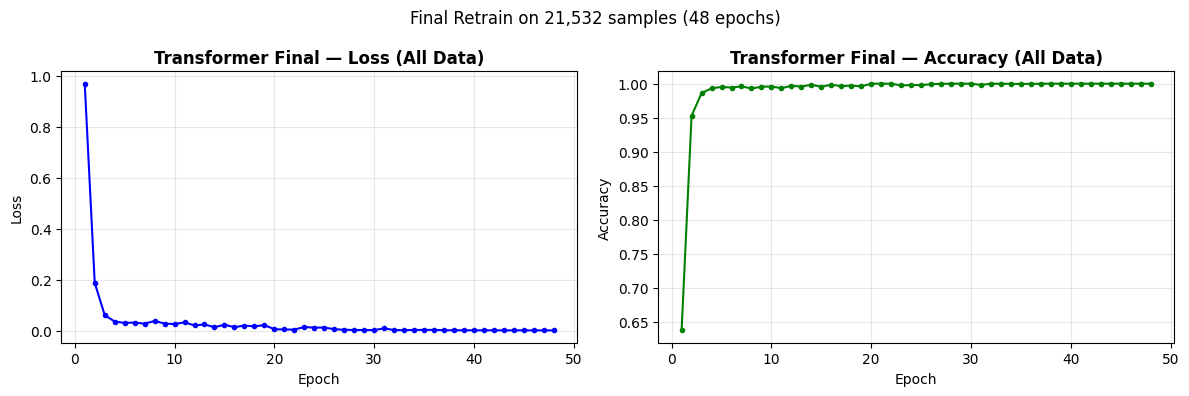

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\final_training_results.png


In [17]:
# ==== CELL 16: Plot retrain learning curve ====
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ep_range = range(1, len(retrain_history.history['loss']) + 1)

ax1.plot(ep_range, retrain_history.history['loss'], 'b-o', markersize=3)
ax1.set_title(f'{WINNER_NAME} Final — Loss (All Data)', fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.grid(True, alpha=0.3)

ax2.plot(ep_range, retrain_history.history['accuracy'], 'g-o', markersize=3)
ax2.set_title(f'{WINNER_NAME} Final — Accuracy (All Data)', fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy'); ax2.grid(True, alpha=0.3)

plt.suptitle(f'Final Retrain on {len(X_all):,} samples ({BEST_EPOCH} epochs)', fontsize=12)
plt.tight_layout()
retrain_png = os.path.join(FINAL_MODEL_DIR, 'final_training_results.png')
plt.savefig(retrain_png, dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved: {retrain_png}')

In [18]:
# ==== CELL 17: Tong ket ====
print('=' * 55)
print('           HOAN THANH!')
print('=' * 55)
print(f'  Winner model  : {WINNER_NAME}')
print(f'  Best epoch    : {BEST_EPOCH}')
print(f'  Retrain data  : {len(X_all):,} samples (100% data)')
print(f'  Final model   : {final_model_path}')
print(f'  Compare report: {report_path}')
print()
print('=> Tiep theo: Sprint 3 — Viet ml_backend/ (FastAPI + predictor)')

           HOAN THANH!
  Winner model  : Transformer
  Best epoch    : 48
  Retrain data  : 21,532 samples (100% data)
  Final model   : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\transformer\final_model.h5
  Compare report: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\reports\comparison_report.json

=> Tiep theo: Sprint 3 — Viet ml_backend/ (FastAPI + predictor)
